<a href="https://colab.research.google.com/github/durgajc/portfolio_durga/blob/ai-ml/SDP3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TOPIC1-homeprices-ML-DAY3

In [355]:
import pandas as pd
import numpy as np
from sklearn import linear_model
import matplotlib.pyplot as plt

In [356]:
df=pd.read_csv('homeprices.csv')
df

,area,price
0,2600,550000
1,3000,565000
2,3200,610000
3,3600,680000
4,4000,725000


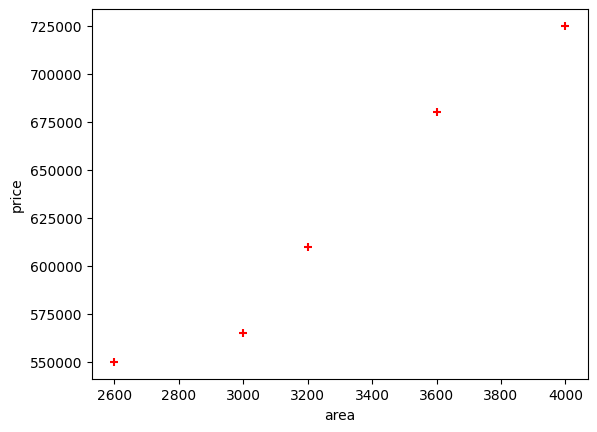

In [357]:
#first we need to analysis (visualize our data)
plt.xlabel('area')
plt.ylabel('price')
plt.scatter(df.area,df.price,color='red',marker='+')

In [358]:
'''
#Formula
y=mx+b
home price = m * (area) + b
'''

new_df=df.drop('price',axis='columns')
new_df

,area
0,2600
1,3000
2,3200
3,3600
4,4000


In [359]:
#output daata for our ML model
price=df.price
price

,price
0,550000
1,565000
2,610000
3,680000
4,725000


In [360]:
#Create linear regression object
reg=linear_model.LinearRegression()
#Training our model
reg.fit(new_df,price)

LinearRegression()

In [361]:
#predict price of a home with area = 3300 sqr ft
reg.predict([[3300]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([628715.75342466])

In [362]:
reg.coef_ #slope (m)

array([135.78767123])

In [363]:
reg.intercept_ #intercept (b)

np.float64(180616.43835616432)

In [364]:
'''# Y = m * X + b (m is coefficient and b is intercept)
3300*'''

'# Y = m * X + b (m is coefficient and b is intercept)\n3300*'

In [365]:
reg.predict([[5500]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([927448.63013699])

# Topic2-insurance_data.

In [366]:
import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline

In [367]:
data=pd.read_csv("insurance_data.csv")
data.head()

,age,bought_insurance
0,22,0
1,25,0
2,47,1
3,52,0
4,46,1


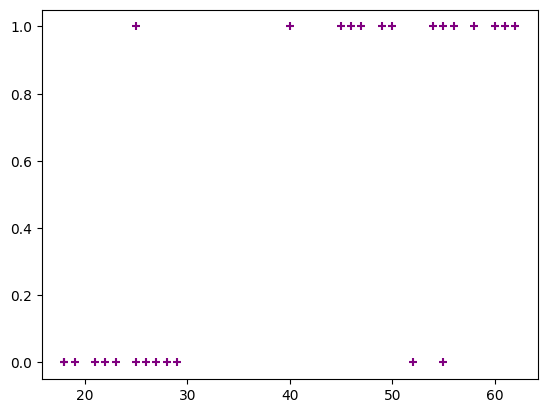

In [368]:
plt.scatter(data.age,data.bought_insurance,marker='+', color='purple')

In [369]:
from sklearn.model_selection import train_test_split

In [370]:
x_train, x_test, y_train, y_test = train_test_split(data[['age']],data.bought_insurance,train_size=0.8)

In [371]:
x_test

,age
21,26
20,21
7,60
17,58
0,22
25,54


In [372]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [373]:
#Training our model
model.fit(x_train,y_train)

LogisticRegression()

In [374]:
x_test

,age
21,26
20,21
7,60
17,58
0,22
25,54


In [375]:
y_predicted = model.predict(x_test)
y_predicted

array([0, 0, 1, 1, 0, 1])

In [376]:
#proba is a probability method
model.predict_proba(x_test)

array([[0.80651236, 0.19348764],
       [0.88094489, 0.11905511],
       [0.07762696, 0.92237304],
       [0.09574061, 0.90425939],
       [0.86837058, 0.13162942],
       [0.14352065, 0.85647935]])

In [377]:
model.predict([[18]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [378]:
model.predict_proba([[18]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([[0.91259585, 0.08740415]])

In [379]:
#Finding the accuracy of the model
model.score(x_test,y_test)

1.0

# Topic3-Accuracy

In [380]:
from sklearn.metrics import classification_report

In [381]:
y_predicted=model.predict(x_test)

In [382]:
print(classification_report(y_test,y_predicted))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



# Topic4-KNN

In [383]:
import pandas as pd
from sklearn.datasets import load_iris
iris=load_iris()
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [384]:
iris.feature_names=['sepal length (cm)','sepal width (cm)','petal length (cm)','petal width (cm)']
iris.target_names=['setosa','versicolor','virginica']
print(iris.feature_names)
print(iris.target_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa', 'versicolor', 'virginica']


In [385]:
d=pd.DataFrame(iris.data,columns=iris.feature_names)
d.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [386]:
d0=d[:50]
d1=d[50:100]
d2=d[100:]

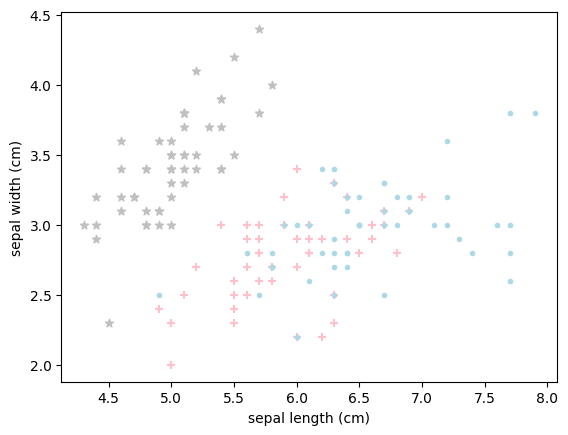

In [387]:
import matplotlib.pyplot as plt
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.scatter(d0['sepal length (cm)'],d0['sepal width (cm)'],color='silver',marker='*')

plt.scatter(d1['sepal length (cm)'],d1['sepal width (cm)'],color='pink',marker='+')

plt.scatter(d2['sepal length (cm)'],d2['sepal width (cm)'],color='lightblue',marker='.')

In [388]:
from sklearn.model_selection import train_test_split
x=iris.data
y=iris.target
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2)

In [389]:
len(x_train)

120

In [390]:
len(x_test)

30

In [391]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=10)

In [392]:
knn.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=10)

In [393]:
knn.score(x_test,y_test)

1.0

In [394]:
y_predicted=knn.predict(x_test)
y_predicted

array([1, 2, 2, 2, 0, 2, 0, 1, 0, 2, 2, 1, 2, 2, 2, 0, 1, 1, 1, 0, 0, 1,
       0, 1, 1, 2, 2, 0, 1, 1])

In [395]:
unknown_data=[[1.1,4.3,1.2,1.2]]

In [396]:
y_predicted=knn.predict(unknown_data)
y_predicted


array([0])

In [400]:
print("prediction flower is: ",iris.target_names[y_predicted[0]])

prediction flower is:  setosa
